In [1]:
import logging

import numpy as np
import optimistix as optx
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from scipy.signal import savgol_filter


logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)

Atmodeller initialized with double precision (float64)


# Sub-Neptune (e.g. K2-18b) models from Bower et al. (2025)

The code blocks below must always be run, but then you can preferentially run only the models for ideal or real gases.

Parameters for the simulations

In [2]:
eos_models = get_eos_models()
sol_models = get_solubility_models()

# Gases 
H2O_gs = Species.create_gas(
    "H2O", 
    solubility=sol_models["H2O_peridotite_sossi23"]
    )
H2O_rgs = Species.create_gas(
    "H2O", 
    activity=eos_models["H2O_cork_holland98"],
    solubility=sol_models["H2O_peridotite_sossi23"]
    )

H2_gs = Species.create_gas(
    "H2", 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )
H2_rgs = Species.create_gas(
    "H2", 
    activity=eos_models["H2_chabrier21"], 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )

O2_g = Species.create_gas(
    "O2"
    )
O2_rg = Species.create_gas(
    "O2", 
    activity=eos_models["O2_cs_shi92"]
    )


CO2_gs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"]
)

CO2_rgs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"], activity=eos_models["CO2_cs_shi92"]
)

CO_gs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"]
)
CO_rgs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"], activity=eos_models["CO_cs_shi92"]
)

CH4_gs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"]
)
CH4_rgs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"], activity=eos_models["CH4_cs_shi92"]
)

N2_gs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"]
)
N2_rgs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"], activity=eos_models["N2_cs_saxena87"]
)

NH3_g = Species.create_gas("H3N")
NH3_rg = Species.create_gas("H3N", activity=eos_models["H3N_rk49_reid87"])


CHN_g = Species.create_gas("CHN")
CHN_rg = Species.create_gas("CHN", activity=eos_models["CHN_rk49_reid87"])

He_gs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"]
)
He_rgs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"], activity=eos_models["He_chabrier21"]
)


species_ideal = SpeciesCollection(
    (
        H2O_gs,
        H2_gs,
        O2_g,
        CO2_gs,
        CO_gs,
        CH4_gs,
        N2_gs,
        NH3_g,
        CHN_g,
        He_gs,
    )
)

species_real = SpeciesCollection(
    (
        H2O_rgs,
        H2_rgs,
        O2_rg,
        CO2_rgs,
        CO_rgs,
        CH4_rgs,
        N2_rgs,
        NH3_rg,
        CHN_rg,
        He_rgs,
    )
)

In [24]:
number_of_realisations = 50
surface_temperature = 3000  # K

# For simulations with fixed mass and surface radius:
planet_mass = 5.154e25
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018
mantle_melt_fraction = 1  # 0.1

ALL_VALUES = []

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

## Hydrogen fraction

Where does saturation occur

In [25]:
import numpy as np

# ===========================================================
# 1. Lodders (2009) solar composition mass fractions (wt%)
# ===========================================================
H_masspercent_lodders09  = 73.9
He_masspercent_lodders09 = 24.69
C_masspercent_lodders09  = 0.22
N_masspercent_lodders09  = 0.07
O_masspercent_lodders09  = 0.63

# Ratios relative to hydrogen (Solar)
C_H_RATIO_SOLAR  = C_masspercent_lodders09  / H_masspercent_lodders09
N_H_RATIO_SOLAR  = N_masspercent_lodders09  / H_masspercent_lodders09
O_H_RATIO_SOLAR  = O_masspercent_lodders09  / H_masspercent_lodders09
He_H_RATIO_SOLAR = He_masspercent_lodders09 / H_masspercent_lodders09


# ===========================================================
# 2. Function to get metal-enriched budgets
# ===========================================================
def get_enriched_budget(h_kg, metallicity_factor=100):
    """
    Returns C, N, O, and He masses based on solar H ratios,
    with C, N, O enriched by metallicity_factor × solar.
    He stays fixed at the solar He/H ratio.
    """
    return {
        "H":  h_kg,
        "C":  h_kg * C_H_RATIO_SOLAR  * metallicity_factor,
        "N":  h_kg * N_H_RATIO_SOLAR  * metallicity_factor,
        "He": h_kg * He_H_RATIO_SOLAR
    }


# ===========================================================
# 3. Hydrogen mass fraction range: 0.1% → 10% of total planet mass
# ===========================================================
number_of_realisations = 50   # choose as needed

# Hydrogen mass fractions between 0.001 and 0.10
H_mass_fraction = np.logspace(-3, -1, number_of_realisations)
fO2_log10_shifts = np.full(number_of_realisations, 0)

# Convert mass fraction → hydrogen mass in kg
h_kg = H_mass_fraction * planet_mass

mass_constraints = get_enriched_budget(h_kg, metallicity_factor=100)

In [19]:
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

In [20]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)
model_ideal_varyfO2andH_withsol = InteriorAtmosphere(species_real)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model_ideal_varyfO2andH_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)

output_model_ideal_varyfO2andH_withsol = model_ideal_varyfO2andH_withsol.output

# Write the complete solution to Excel
file = output_model_ideal_varyfO2andH_withsol.to_excel("FILE200")

# Write the data to a pickle file with dataframes
output_model_ideal_varyfO2andH_withsol.to_pickle("FILE200")



[20:59:36 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[20:59:36 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[20:59:36 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[20:59:36 - atmodeller.classes             - IN

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import get_cmap
from matplotlib.ticker import ScalarFormatter, FixedLocator

# ===========================================================
# STYLE
# ===========================================================
def set_style():
    plt.rcdefaults()
    plt.rcParams["font.family"] = "serif"
    plt.rcParams["axes.labelsize"] = 15
    plt.rcParams["axes.titlesize"] = 16
    plt.rcParams["legend.fontsize"] = 12
    plt.rcParams["axes.grid"] = True
    plt.rcParams["grid.linestyle"] = ":"
    plt.rcParams["grid.alpha"] = 0.4

# Stacked area colors (unchanged)
palette = get_cmap("Set2")(np.linspace(0, 1, 4))

# Ratio line colors
ratio_colors = {
    "mass": "black",
    "mole": "black"
}

# ===========================================================
# HELPERS
# ===========================================================
def load_species(file, sheet):
    return pd.read_excel(file, sheet_name=sheet)

def compute_mass_partition(df_H2O, df_H2):
    H2O_atm = df_H2O["atmosphere_mass"]
    H2O_mag = df_H2O["dissolved_mass"]
    H2_atm  = df_H2["atmosphere_mass"]
    H2_mag  = df_H2["dissolved_mass"]
    total = H2O_atm + H2O_mag + H2_atm + H2_mag
    return (H2O_atm/total, H2O_mag/total, H2_atm/total, H2_mag/total)

def compute_mole_partition(df_H2O, df_H2):
    H2O_atm = df_H2O["atmosphere_moles"]
    H2O_mag = df_H2O["dissolved_moles"]
    H2_atm  = df_H2["atmosphere_moles"]
    H2_mag  = df_H2["dissolved_moles"]
    total = H2O_atm + H2O_mag + H2_atm + H2_mag
    return (H2O_atm/total, H2O_mag/total, H2_atm/total, H2_mag/total)

def get_x_axis(df_H2O, df_H2, planet_mass):
    return (df_H2O["total_mass"] + df_H2["total_mass"]) / planet_mass

def load_mass_frac(file):
    df_H2  = pd.read_excel(file, sheet_name="H2_g")
    df_H2O = pd.read_excel(file, sheet_name="H2O_g")
    return df_H2["atmosphere_mass"] / df_H2O["atmosphere_mass"]

def load_moles_frac(file):
    df_H2  = pd.read_excel(file, sheet_name="H2_g")
    df_H2O = pd.read_excel(file, sheet_name="H2O_g")
    return df_H2["atmosphere_moles"] / df_H2O["atmosphere_moles"]


def mmw(file):

    molar_masses = {
    'H2_g': 2.016,
    'H2O_g': 18.015,
    'CO_g': 28.010,
    'CO2_g': 44.009,
    'CH4_g': 16.043,
    'N2_g': 28.014,
    'O2_g': 31.998,
    'H3N_g': 17.031,
    'He_g': 4.003,
    }

    mmw = 0
    
    for species, molar_mass in molar_masses.items():
        df = pd.read_excel(file, sheet_name=species)
        volume_mixing_ratio = df["volume_mixing_ratio"]
        weight = volume_mixing_ratio * molar_mass
        mmw += weight

    return mmw
    



# ===========================================================
# MAIN FUNCTION
# ===========================================================
def plot_all(files, outfile="partitioning_plots.png"):

    set_style()

    mantle_values = [1.0, 0.5, 0.1]
    x_ticks = [0.1, 1, 10]

    fig, axes = plt.subplots(3, 2, figsize=(14, 18), dpi=200)

    # Global title
    fig.suptitle("H₂ and H₂O Partitioning with varying mantle melt fraction ($M_{{frac}}$)", fontsize=22, y=0.96)

    for i, file in enumerate(files):

        df_planet = pd.read_excel(file, sheet_name="planet")
        df_H = pd.read_excel(file, sheet_name="element_H")
        df_H2O = load_species(file, "H2O_g")
        df_H2  = load_species(file, "H2_g")

        planet_mass = df_planet["planet_mass"].iloc[0]
        XX = (df_H["total_mass"] / planet_mass) * 100

        # 4-area partitions
        mf_H2O_atm, mf_H2O_mag, mf_H2_atm, mf_H2_mag = compute_mass_partition(df_H2O, df_H2)
        xf_H2O_atm, xf_H2O_mag, xf_H2_atm, xf_H2_mag = compute_mole_partition(df_H2O, df_H2)

        # Ratio lines
        mass_ratio = load_mass_frac(file)
        mole_ratio = load_moles_frac(file)
        MMW = mmw(file)

        Mfrac = mantle_values[i]

        # =====================================================
        # LEFT COLUMN — MASS FRACTION
        # =====================================================
        ax = axes[i, 0]

        ax.stackplot(
            XX,
            mf_H2O_atm, mf_H2O_mag, mf_H2_atm, mf_H2_mag,
            labels=["H₂O atm", "H₂O magma", "H₂ atm", "H₂ magma"],
            colors=palette, alpha=0.85
        )

        ax.set_xscale("log")
        ax.set_xlim(min(XX), 10)
        ax.xaxis.set_major_locator(FixedLocator(x_ticks))

        fmt = ScalarFormatter(); fmt.set_scientific(False)
        ax.xaxis.set_major_formatter(fmt)

        ax.set_ylim(0, 1)
        ax.set_ylabel("Partitioning (Mass Fraction)")
        ax.set_xlabel("Total Hydrogen Mass / Planet Mass  [%]")

        ax.set_title(f"Mass fraction, $M_{{frac}}$ = {Mfrac}")

        # MASS RATIO LINE
        ax_mmw = ax.twinx()
        mass_line = ax_mmw.plot(
            XX, MMW,
            color=ratio_colors["mass"],
            lw=2.3,
            label="mmw"
        )[0]
        ax_mmw.set_ylabel("mean molecular weight")

        # Legend
        handles1, labels1 = ax.get_legend_handles_labels()
        handles = handles1 + [mass_line]
        labels  = labels1 + ["mmw"]
        if i == 0:
            ax.legend(handles, labels, loc="upper left", frameon=True, fontsize=10)

        # =====================================================
        # RIGHT COLUMN — MOLE FRACTION
        # =====================================================
        ax2 = axes[i, 1]

        ax2.stackplot(
            XX,
            xf_H2O_atm, xf_H2O_mag, xf_H2_atm, xf_H2_mag,
            labels=["H₂O atm", "H₂O magma", "H₂ atm", "H₂ magma"],
            colors=palette, alpha=0.85
        )

        ax2.set_xscale("log")
        ax2.set_xlim(min(XX), 10)
        ax2.xaxis.set_major_locator(FixedLocator(x_ticks))
        ax2.xaxis.set_major_formatter(fmt)

        ax2.set_ylim(0, 1)
        ax2.set_ylabel("Partitioning (Mole Fraction)")
        ax2.set_xlabel("Total Hydrogen Mass / Planet Mass  [%]")

        ax2.set_title(f"Mole fraction, $M_{{frac}}$ = {Mfrac}")

        # MOLE RATIO LINE
        ax3 = ax2.twinx()
        mole_line = ax3.plot(
            XX, MMW,
            color=ratio_colors["mole"],
            lw=2.3,
            label="mmw"
        )[0]
        ax3.set_ylabel("mean molecular weight")

        # Legend
        handles2, labels2 = ax2.get_legend_handles_labels()
        handles2 = handles2 + [mole_line]
        labels2  = labels2 + ["H₂/H₂O (mole)"]
        if i == 0 :
            ax2.legend(handles2, labels2, loc="upper left", frameon=True, fontsize=10)

    plt.subplots_adjust(wspace=0.5, hspace=0.35)
    plt.tight_layout(rect=[0, 0, 1, 0.96])  # leave space for global title
    plt.savefig(outfile, dpi=300, bbox_inches="tight")
    plt.show()


/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_48356/2974519284.py:21: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette = get_cmap("Set2")(np.linspace(0, 1, 4))


In [ ]:
#partial pressure vs surface temperature REAL
FILE = "cool_sub_neptune_real_withsol_varyT.xlsx"  # REAL-gas, varying T

# Sheets corresponding to gas species
CANDIDATE_SHEETS = [
    "H2_g", "H2O_g", "O2_g", "CO_g", "CO2_g",
    "CH4_g", "N2_g", "NH3_g", "CHN_g", "He_g"
]

# ----------------------------
# LOAD WORKBOOK
# ----------------------------
xls = pd.ExcelFile(FILE)
available_gas_sheets = [s for s in CANDIDATE_SHEETS if s in xls.sheet_names]
print("Gas sheets found:", available_gas_sheets)

# ----------------------------
# X-AXIS: surface temperature (K) from 'planet' sheet
# ----------------------------
planet_df = pd.read_excel(FILE, sheet_name="planet")
surface_T = planet_df["surface_temperature"].to_numpy()    # in K

# sort by increasing temperature
order = np.argsort(surface_T)
surface_T = surface_T[order]

# ----------------------------
# Y-AXIS: partial pressures for each species
# ----------------------------
species_pressures = {}

for sheet in available_gas_sheets:
    df = pd.read_excel(FILE, sheet_name=sheet)
    p_bar = df["pressure"].to_numpy()          # in bar
    species_pressures[sheet] = p_bar[order]

# ----------------------------
# PLOT (LEFT: bar, RIGHT: GPa)
# ----------------------------
fig, ax_bar = plt.subplots(figsize=(8, 5))

for sheet, p_bar in species_pressures.items():
    ax_bar.plot(surface_T, p_bar, label=sheet)

ax_bar.set_xlabel("Surface temperature [K]")
ax_bar.set_ylabel("Partial pressure (bar)")
ax_bar.set_yscale("log")

# ----------------------------
# RIGHT AXIS IN GPa
# ----------------------------
def bar_to_gpa(y_bar):
    return y_bar * 1e-4     # 1 bar = 1e-4 GPa

ax_gpa = ax_bar.twinx()
ymin_bar, ymax_bar = ax_bar.get_ylim()
ax_gpa.set_ylim(bar_to_gpa(ymin_bar), bar_to_gpa(ymax_bar))
ax_gpa.set_ylabel("Partial pressure (GPa)")
ax_gpa.set_yscale("log")

# ----------------------------
# AESTHETICS
# ----------------------------
plt.title("REAL-gas partial pressures vs surface temperature")
ax_bar.grid(True, which="both", linestyle="--", alpha=0.35)
ax_bar.legend(title="Gas species", loc="best")

plt.tight_layout()
plt.show()

In [26]:


surface_temperatures = np.linspace(1800, 3500, number_of_realisations)
fO2_log10_shift_fixed = np.full(number_of_realisations, 0)


# Planet with vectorized properties (one per realisation)
cool_sub_neptune = Planet(
    surface_temperature=surface_temperatures,
    planet_mass=planet_mass,   
    surface_radius=surface_radius, 
    mantle_melt_fraction=mantle_melt_fraction,
)

solver_parameters = SolverParameters(solver=optx.LevenbergMarquardt)


# Fixed fO2 for all planets via IW buffer
fugacity_constraints = {
    O2_rg.name: IronWustiteBuffer(fO2_log10_shift_fixed)
}

model_real = InteriorAtmosphere(species_real)

model_real.solve(
    planet=cool_sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
out_real = model_real.output

out_real.to_excel("cool_sub_neptune_real_withsol_varyT")

out_real.to_pickle("cool_sub_neptune_real_withsol_varyT.pkl")

[12:44:12 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[12:44:12 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[12:44:12 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[12:44:12 - atmodeller.classes             - IN

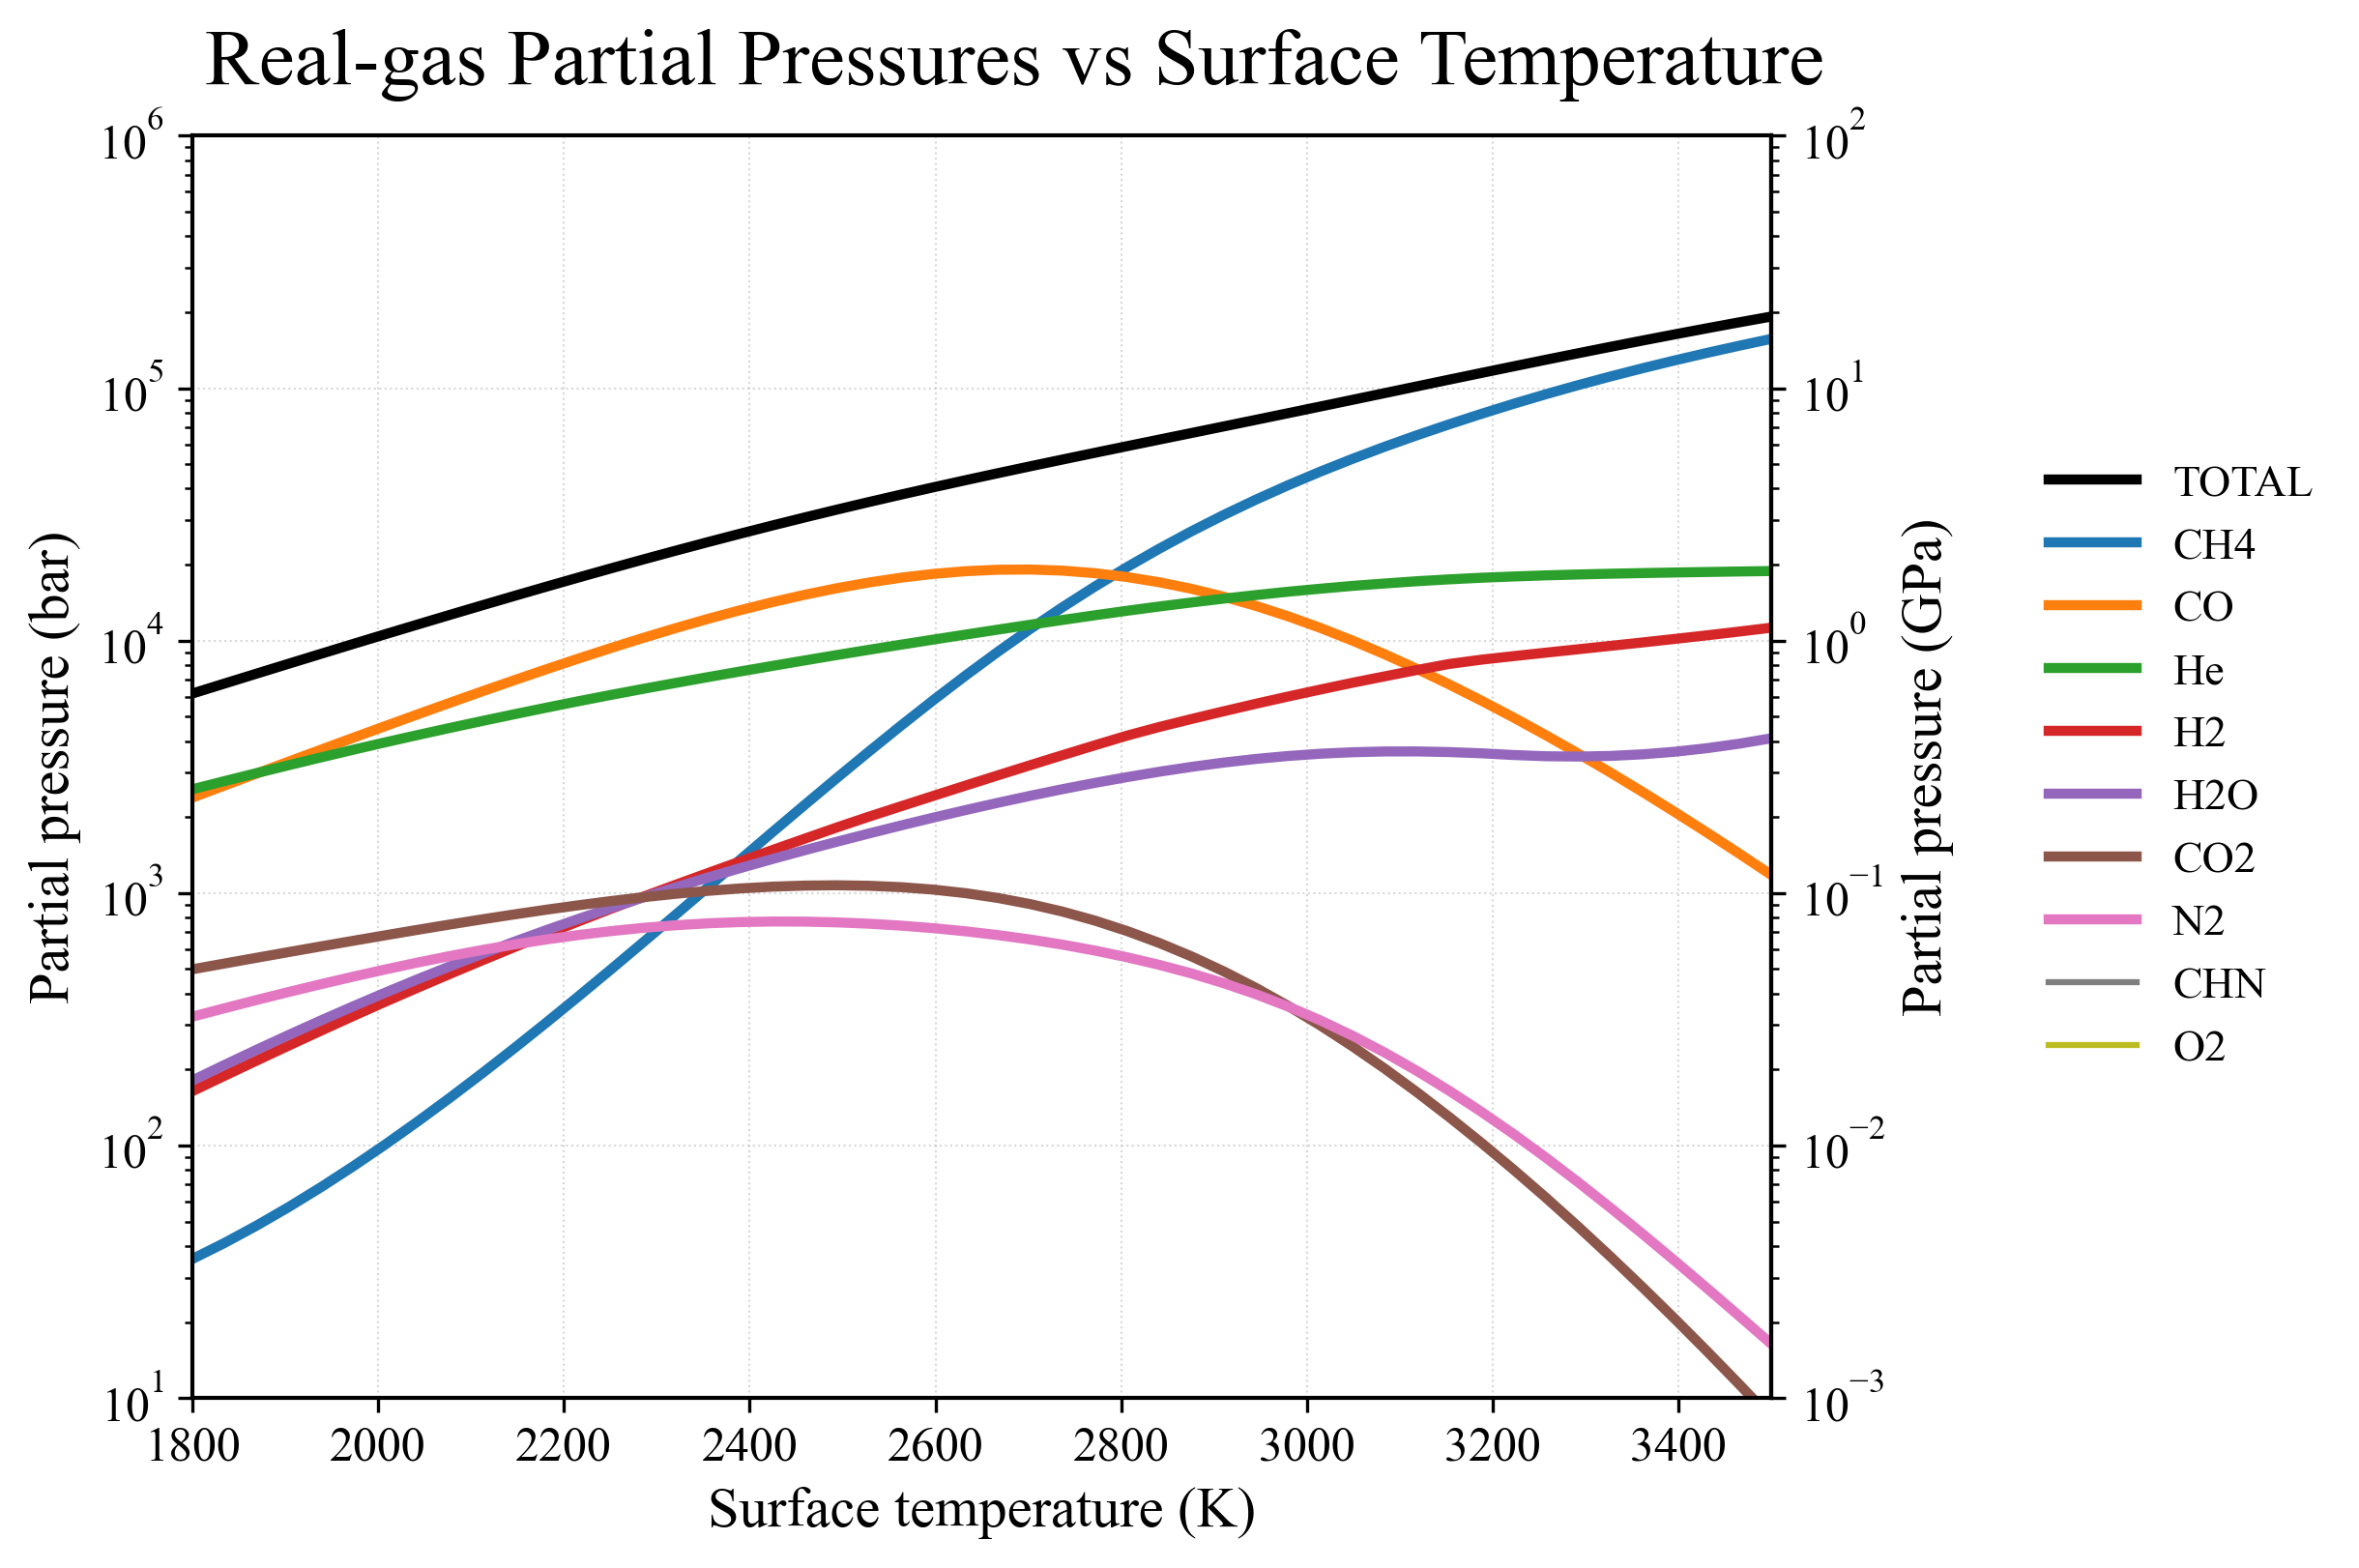

In [75]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
from matplotlib import colormaps

# ===========================================================
# NATURE-STYLE SETUP
# ===========================================================
def set_nature_style():
    plt.rcdefaults()
    plt.rcParams["font.family"] = "serif"
    plt.rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif"]
    plt.rcParams["axes.labelsize"] = 14
    plt.rcParams["xtick.labelsize"] = 12
    plt.rcParams["ytick.labelsize"] = 12
    plt.rcParams["legend.fontsize"] = 11
    plt.rcParams["axes.linewidth"] = 1.0
    plt.rcParams["axes.grid"] = True
    plt.rcParams["grid.linestyle"] = ":"
    plt.rcParams["grid.linewidth"] = 0.5
    plt.rcParams["grid.alpha"] = 0.5
    plt.rcParams["axes.prop_cycle"] = plt.cycler(color=colormaps["tab10"].colors)

# ===========================================================
# HELPER: Unit Conversion
# ===========================================================
def bar_to_gpa(x):
    return x * 1e-4

def gpa_to_bar(x):
    return x * 1e4

# ===========================================================
# MAIN FIGURE
# ===========================================================
def plot_partial_pressure_temperature(file):
    
    set_nature_style()

    # Define Gas sheets
    CANDIDATE_SHEETS = [
        "H2_g", "H2O_g", "O2_g", "CO_g", "CO2_g",
        "CH4_g", "N2_g", "NH3_g", "CHN_g", "He_g"
    ]

    # --- Data Loading ---
    try:
        xls = pd.ExcelFile(file)
        available = [s for s in CANDIDATE_SHEETS if s in xls.sheet_names]
        
        planet_df = pd.read_excel(file, sheet_name="planet")
        surface_T = planet_df["surface_temperature"].to_numpy()
        order = np.argsort(surface_T)
        surface_T = surface_T[order]

        species_pressures = {}
        for sheet in available:
            df = pd.read_excel(file, sheet_name=sheet)
            p_bar = df["pressure"].to_numpy()
            species_pressures[sheet] = p_bar[order]
            
    except Exception as e:
        print(f"Data load error: {e}")
        return

    # ======================================================
    # FIGURE GENERATION
    # ======================================================
    fig, ax_bar = plt.subplots(figsize=(8, 5), dpi=300, layout="constrained")

    # Define species to de-emphasize
    # These will be plotted faintly to avoid clutter but acknowledge existence
    GHOST_SPECIES = ["CHN_g", "O2_g"]

    # SORTING LOGIC:
    # Sort keys based on the maximum pressure value found in their data array.
    # reverse=True puts the highest (strongest) pressure first.
    sorted_species = sorted(
        species_pressures.keys(), 
        key=lambda k: np.max(species_pressures[k]), 
        reverse=True
    )

    atm_df = pd.read_excel(file, sheet_name="atmosphere")
    total_pressure = atm_df["pressure"]
    ax_bar.plot(surface_T, total_pressure, lw=2.5, label='TOTAL', alpha=1.0, color='black')

    # Plot lines in sorted order
    for sheet in sorted_species:
        p_bar = species_pressures[sheet]
        label_name = sheet.replace("_g", "") # Clean label
        
        if sheet in GHOST_SPECIES:
            # STYLE FOR "NEGLIGIBLE" SPECIES
            # We plot EMPTY lists ([], []). 
            # This advances the color cycle and adds the name to the legend,
            # but draws absolutely nothing on the canvas to prevent "clumping".
            ax_bar.plot([], [], label=label_name)
        else:
            # STYLE FOR DOMINANT SPECIES
            ax_bar.plot(surface_T, p_bar, lw=2.5, label=label_name, alpha=1.0)

    # -------- Left Axis (Bar) --------
    ax_bar.set_xlabel("Surface temperature (K)")
    ax_bar.set_ylabel("Partial pressure (bar)")
    ax_bar.set_yscale("log")
    
    # HARD CUTOFF: This hides the data below 10^-7 scientifically 
    # (effectively saying it's below the noise floor)
    ax_bar.set_ylim([10**1, 10**6])
    ax_bar.set_xlim([1800, 3500])
    ax_bar.xaxis.set_major_locator(ticker.MultipleLocator(200))

    # Log Formatting
    ax_bar.yaxis.set_major_locator(ticker.LogLocator(base=10, numticks=12))
    ax_bar.yaxis.set_major_formatter(ticker.LogFormatterMathtext())
    
    # -------- Right Axis (GPa) --------
    ax_gpa = ax_bar.secondary_yaxis('right', functions=(bar_to_gpa, gpa_to_bar))
    ax_gpa.set_ylabel("Partial pressure (GPa)")
    ax_gpa.yaxis.set_major_locator(ticker.LogLocator(base=10, numticks=12))
    ax_gpa.yaxis.set_major_formatter(ticker.LogFormatterMathtext())
    
    # Corrected Title Syntax (using ha='center')
    fig.suptitle("Real-gas Partial Pressures vs Surface Temperature", fontsize=20, ha="center", x=0.43, y=1.05)

    # -------- Legend --------
    ax_bar.legend(
        frameon=False,
        loc="center left", 
        bbox_to_anchor=(1.15, 0.5)
    )
    
    plt.show()

# ===========================================================
# RUN
# ===========================================================
if __name__ == "__main__":
    # Create dummy data for testing
    import os
    filename = "cool_sub_neptune_real_withsol_varyT.xlsx"
    if not os.path.exists(filename):
        with pd.ExcelWriter(filename) as writer:
            T = np.linspace(1800, 3500, 50)
            pd.DataFrame({"surface_temperature": T}).to_excel(writer, sheet_name="planet")
            # Generate dummy data including the "Ghost" species dropping low
            for i, gas in enumerate(["H2_g", "H2O_g", "CH4_g", "CO_g", "N2_g", "CHN_g"]):
                # Make CO and CHN drop drastically to test the faint lines
                if gas in ["O2_g", "CHN_g"]:
                    p = 10**(np.linspace(2, -18, 50)) 
                else:
                    p = 10**(np.linspace(5 - i, -2 - i, 50)) 
                pd.DataFrame({"pressure": p}).to_excel(writer, sheet_name=gas)

    plot_partial_pressure_temperature(filename)

In [63]:


surface_temperature = 3000
melts = np.linspace(0.1, 1, number_of_realisations)
fO2_log10_shift_fixed = np.full(number_of_realisations, 0)


# Planet with vectorized properties (one per realisation)
cool_sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,   
    surface_radius=surface_radius, 
    mantle_melt_fraction=melts,
)

solver_parameters = SolverParameters(solver=optx.LevenbergMarquardt)


# Fixed fO2 for all planets via IW buffer
fugacity_constraints = {
    O2_rg.name: IronWustiteBuffer(fO2_log10_shift_fixed)
}

model_real = InteriorAtmosphere(species_real)

model_real.solve(
    planet=cool_sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
out_real = model_real.output

out_real.to_excel("cool_sub_neptune_real_withsol_varymelt")

out_real.to_pickle("cool_sub_neptune_real_withsol_varymelt")

[13:24:25 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[13:24:25 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[13:24:25 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[13:24:25 - atmodeller.classes             - IN

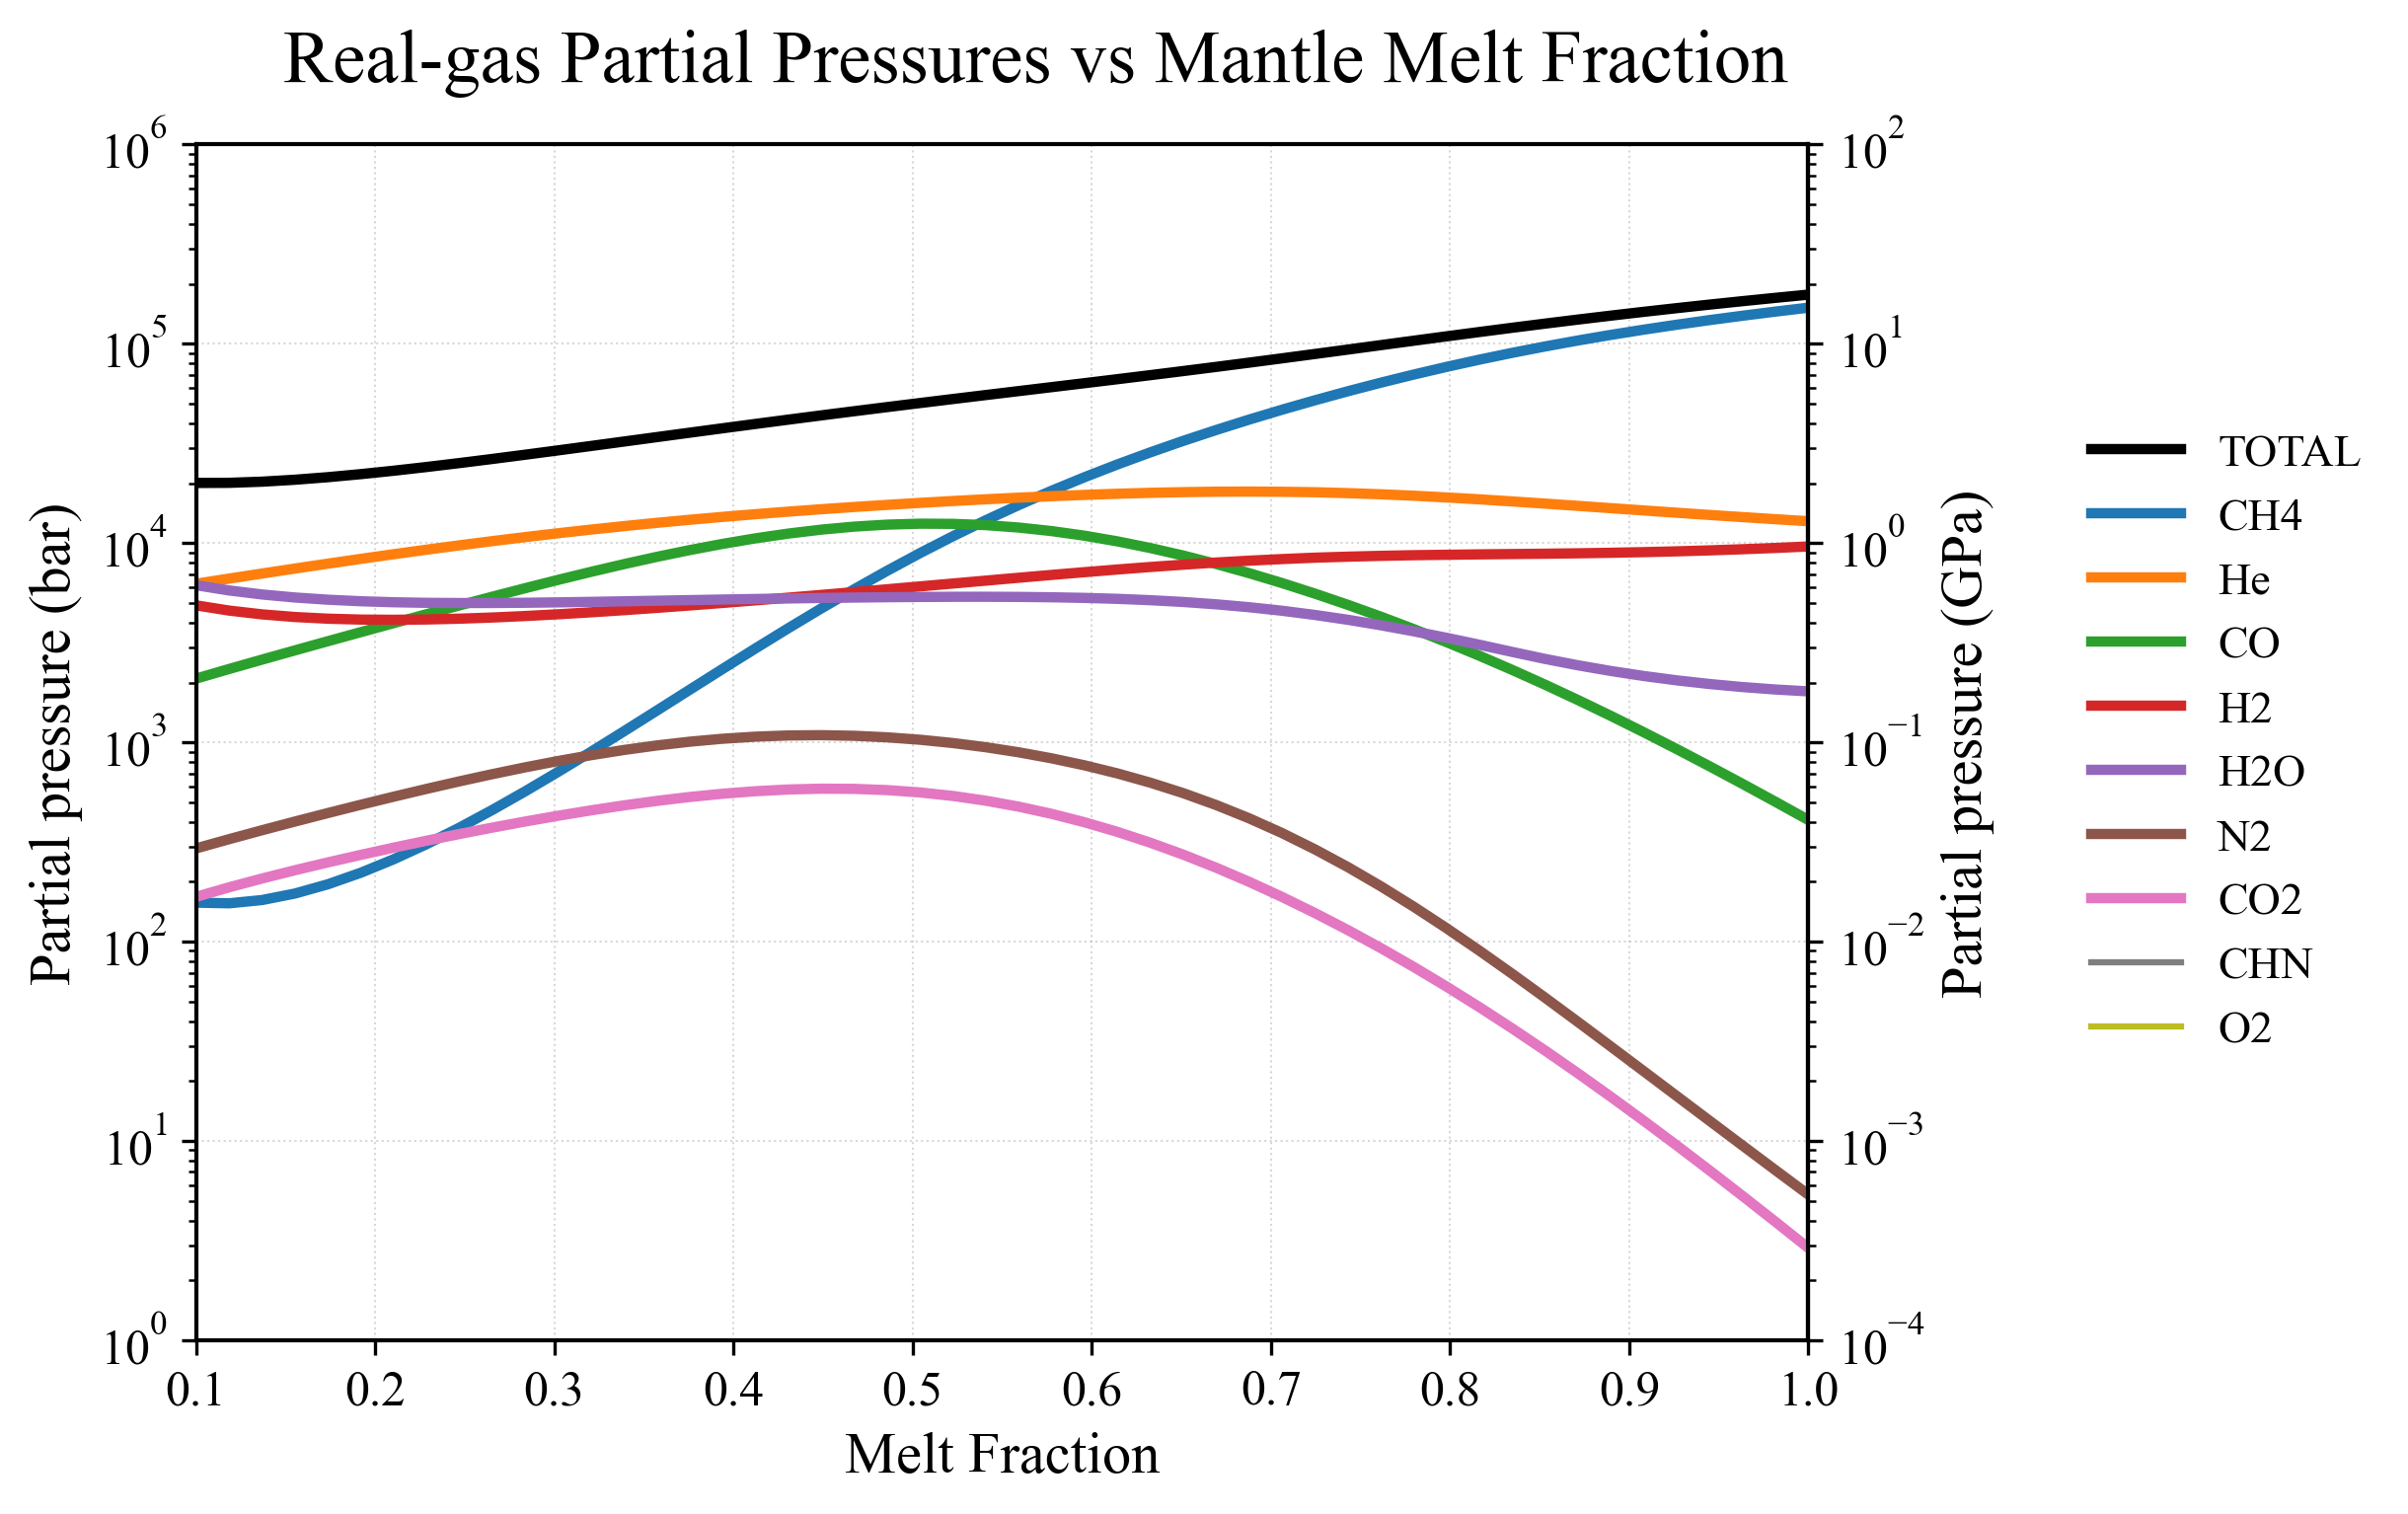

In [78]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
from matplotlib import colormaps
import os

# ===========================================================
# NATURE-STYLE SETUP
# ===========================================================
def set_nature_style():
    plt.rcdefaults()
    plt.rcParams["font.family"] = "serif"
    plt.rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif"]
    plt.rcParams["axes.labelsize"] = 14
    plt.rcParams["xtick.labelsize"] = 12
    plt.rcParams["ytick.labelsize"] = 12
    plt.rcParams["legend.fontsize"] = 11
    plt.rcParams["axes.linewidth"] = 1.0
    plt.rcParams["axes.grid"] = True
    plt.rcParams["grid.linestyle"] = ":"
    plt.rcParams["grid.linewidth"] = 0.5
    plt.rcParams["grid.alpha"] = 0.5
    # Use tab10 for distinct colors
    plt.rcParams["axes.prop_cycle"] = plt.cycler(color=colormaps["tab10"].colors)

# ===========================================================
# HELPER: Unit Conversion
# ===========================================================
def bar_to_gpa(x):
    return x * 1e-4

def gpa_to_bar(x):
    return x * 1e4

# ===========================================================
# MAIN FIGURE
# ===========================================================
def plot_partial_pressure_temperature(file):
    
    set_nature_style()

    # Define Gas sheets
    CANDIDATE_SHEETS = [
        "H2_g", "H2O_g", "O2_g", "CO_g", "CO2_g",
        "CH4_g", "N2_g", "NH3_g", "CHN_g", "He_g"
    ]

    # --- Data Loading ---
    try:
        xls = pd.ExcelFile(file)
        available = [s for s in CANDIDATE_SHEETS if s in xls.sheet_names]
        
        planet_df = pd.read_excel(file, sheet_name="planet")
        
        
        # FIX: Check if we are plotting Temp or Melt. 
        # Based on function name, we default to Temperature.
        if "mantle_melt_fraction" in planet_df.columns:
            x_raw = planet_df["mantle_melt_fraction"].to_numpy()
            xlabel = "Melt Fraction"
        else:
            raise ValueError("Planet sheet missing 'surface_temperature' or 'mantle_melt_fraction'")

        # Sort X-axis to prevent spaghetti plots
        order = np.argsort(x_raw)
        x_data = x_raw[order]

        species_pressures = {}
        for sheet in available:
            df = pd.read_excel(file, sheet_name=sheet)
            p_bar = df["pressure"].to_numpy()
            # FIX: Apply the same sorting order to the pressures
            species_pressures[sheet] = p_bar[order]
            
    except Exception as e:
        print(f"Data load error: {e}")
        return

    # ======================================================
    # FIGURE GENERATION
    # ======================================================
    fig, ax_bar = plt.subplots(figsize=(8, 5), dpi=300, layout="constrained")

    # Define species to de-emphasize (example)
    GHOST_SPECIES = ["CHN_g", "O2_g"]

    atm_df = pd.read_excel(file, sheet_name="atmosphere")
    total_pressure = atm_df["pressure"]
    ax_bar.plot(x_data, total_pressure, lw=2.5, label='TOTAL', alpha=1.0, color='black')

    # SORTING LOGIC:
    # Sort legend keys based on max pressure so dominant species are listed first
    sorted_species = sorted(
        species_pressures.keys(), 
        key=lambda k: np.max(species_pressures[k]), 
        reverse=True
    )

    # Plot lines
    for sheet in sorted_species:
        p_bar = species_pressures[sheet]
        label_name = sheet.replace("_g", "") # Clean label
        
        if sheet in GHOST_SPECIES:
            # STYLE FOR "NEGLIGIBLE" SPECIES
            # Plotting empty list puts it in legend but draws nothing
            ax_bar.plot([], [], label=label_name) 
        else:
            # STYLE FOR DOMINANT SPECIES
            ax_bar.plot(x_data, p_bar, lw=2.5, label=label_name, alpha=1.0)

    # -------- Left Axis (Bar) --------
    ax_bar.set_xlabel(xlabel)
    ax_bar.set_ylabel("Partial pressure (bar)")
    ax_bar.set_yscale("log")
    
    # FIX: Dynamic limits based on data, or hardcoded for Temp
    # Removing the [0.1, 1] limit which was likely for Melt Fraction
    if xlabel == "Melt Fraction":
         ax_bar.set_xlim([0.1, 1])
    else:
        ax_bar.set_xlim([min(x_data), max(x_data)]) 

    ax_bar.set_ylim([10**0, 10**6]) # adjusted to see the dummy data range

    # Log Formatting
    ax_bar.yaxis.set_major_locator(ticker.LogLocator(base=10, numticks=12))
    ax_bar.yaxis.set_major_formatter(ticker.LogFormatterMathtext())
    
    # -------- Right Axis (GPa) --------
    ax_gpa = ax_bar.secondary_yaxis('right', functions=(bar_to_gpa, gpa_to_bar))
    ax_gpa.set_ylabel("Partial pressure (GPa)")
    ax_gpa.yaxis.set_major_locator(ticker.LogLocator(base=10, numticks=12))
    ax_gpa.yaxis.set_major_formatter(ticker.LogFormatterMathtext())
    
    # Title
    fig.suptitle("Real-gas Partial Pressures vs Mantle Melt Fraction", fontsize=18, ha="center", x=0.43)

    # -------- Legend --------
    ax_bar.legend(
        frameon=False,
        loc="center left", 
        bbox_to_anchor=(1.15, 0.5), 
    )
    
    plt.show()

# ===========================================================
# RUN
# ===========================================================
if __name__ == "__main__":
    filename = "cool_sub_neptune_real_withsol_varymelt.xlsx"
    plot_partial_pressure_temperature(filename)

In [13]:
import numpy as np
# from atmodeller import ... (your standard imports)

def calculate_fO2_from_IW(T, delta_IW):
    """
    Uses YOUR Appendix Reaction 6 & 7 to calculate the exact fO2 input.
    delta_IW: The offset from Iron-Wustite buffer (e.g., -1 or +2)
    """
    # Constants from Appendix Reaction 7 (2Fe + O2 <-> 2FeO)
    # The buffer is defined by the equilibrium with pure Fe and FeO.
    # ln K = - dG / RT
    # dG_rxn7 (approx) = -544000 + 130*T (Joules)
    
    dG_IW = -544000 + 130 * T 
    R = 8.314
    
    # ln(K) = ln(1/pO2) = -dG/RT  --> ln(pO2) = dG/RT
    ln_pO2_IW = dG_IW / (R * T)
    log10_pO2_IW = ln_pO2_IW / 2.303
    
    # The fO2 you feed into Atmodeller
    return 10**(log10_pO2_IW + delta_IW)

# --- USAGE IN ATMODELLER ---
# When solving for solubility, you often pass fO2 as an argument:
my_temperature = 2000 # Kelvin
my_fO2 = calculate_fO2_from_IW(my_temperature, delta_IW=-1.5) 

# Example call (hypothetical syntax based on Atmodeller structure)
concentration = solubility_models.concentration(..., fO2=my_fO2)

NameError: name 'solubility_model' is not defined

In [16]:
from atmodeller import Species

# 1. Load the species used in YOUR Reaction 1 (CO2 + CH4 <-> ...)
CO2 = Species.create_gas("CO2")
CH4 = Species.create_gas("CH4")
H2  = Species.create_gas("H2")
CO  = Species.create_gas("CO")
H2O = Species.create_gas("H2O")

# 2. Calculate the Free Energy of Reaction (Delta G) at 1500 K
T = 1500.0
# Atmodeller gives G/RT. We want G in Joules.
R = 8.314
G_CO2 = CO2.data.get_gibbs_over_RT(T) * R * T
G_CH4 = CH4.data.get_gibbs_over_RT(T) * R * T
G_H2  = H2.data.get_gibbs_over_RT(T) * R * T
G_CO  = CO.data.get_gibbs_over_RT(T) * R * T

# 3. Compute Delta G for Reaction 1: 2H2 + 2CO -> CO2 + CH4
# Delta G = G_products - G_reactants
Delta_G_Code = (G_CO2 + G_CH4) - (2*G_H2 + 2*G_CO)

# 4. Compare with YOUR Appendix Formula
# Appendix: dG = -247300 + 256.7 * T
Delta_G_Appendix = -247300 + (256.7 * T)

print(f"Code Delta G: {Delta_G_Code[0]:.2f} J/mol")
print(f"Appendix Delta G: {Delta_G_Appendix:.2f} J/mol")

# If these match, your Thesis Appendix is perfectly consistent with your Code.

Code Delta G: 165472.27 J/mol
Appendix Delta G: 137750.00 J/mol
